# Plant Seedling Classification with CNNs

**Author: Oludotun Babayemi**

## Provenance and reader note
This reviewed notebook preserves saved outputs from the supplied original experiment. It was not re-executed during repository preparation. Setup code has been made local-path friendly, unused imports removed, and interpretations corrected; model definitions and historical training schedules are retained. The saved scores do not validate the modified setup or the separate revised pipeline in `src/`.

The actual split was approximately 81%/9%/10%, not 80%/10%/10%. Historical class IDs map to the species labels shown on the saved confusion matrices; the original numeric-report interpretation was wrong in several places. The second model's test accuracy is 70.95%; this does not establish field readiness.

See `../reports/RESULTS.md`, `../MODEL_CARD.md`, and `../NOTICE.md` for evidence, limitations, dataset attribution and license scope. Dataset images retain their original terms.


## Problem Statement

### Context

Seedling classification can support research into crop and weed identification. This educational project compares two CNN experiments on a 12-species benchmark. Potential agricultural uses require independent field validation, agronomic review and explicit safeguards before intervention decisions.

### Objective

Build and evaluate convolutional neural networks to classify seedling images into 12 species.

### Data Dictionary

The supplied prepared subset contains 4,750 three-channel images at 128 × 128 pixels and a row-aligned `Label` column.

Source: [Plant Seedlings Dataset](https://vision.eng.au.dk/plant-seedlings-dataset/), developed through collaboration between Aarhus University and the University of Southern Denmark. Citation: Giselsson et al. (2017), [A Public Image Database for Benchmark of Plant Seedling Classification Algorithms](https://arxiv.org/abs/1711.05458). Images and annotations carry the provider's CC BY-SA terms.

Expected files: `data/raw/images_plant.npy` and `data/raw/Labels_plant.csv`. The original array construction, source version and row ordering were not supplied. Confirm image-label alignment and source channel order before rerunning.

Species: Black-grass; Charlock; Cleavers; Common Chickweed; Common wheat; Fat Hen; Loose Silky-bent; Maize; Scentless Mayweed; Shepherds Purse; Small-flowered Cranesbill; Sugar beet.

## Importing necessary libraries

In [ ]:
from pathlib import Path
import os
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras import backend
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer


## Loading the dataset

In [ ]:
# Launch Jupyter from the project root or the notebooks directory.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = Path(os.environ.get('PLANT_DATA_DIR', str(PROJECT_ROOT / 'data' / 'raw')))
print('Dataset directory:', DATA_DIR)


In [ ]:
# Original saved outputs used prepared arrays whose provenance is unavailable.
images = np.load(DATA_DIR / 'images_plant.npy', allow_pickle=False)
labels = pd.read_csv(DATA_DIR / 'Labels_plant.csv')
assert images.ndim == 4 and images.shape[-1] == 3
assert len(images) == len(labels) and 'Label' in labels.columns
assert labels['Label'].notna().all()


## Data Overview

### Understand the shape of the dataset

In [ ]:
print(images.shape)         # checking the shape
print(labels.shape)         # checking the shape

(4750, 128, 128, 3)
(4750, 1)


## Exploratory Data Analysis

### Plotting random images from each of the class

One randomly selected image per species is displayed below. Selection in the historical exploration was not seeded.

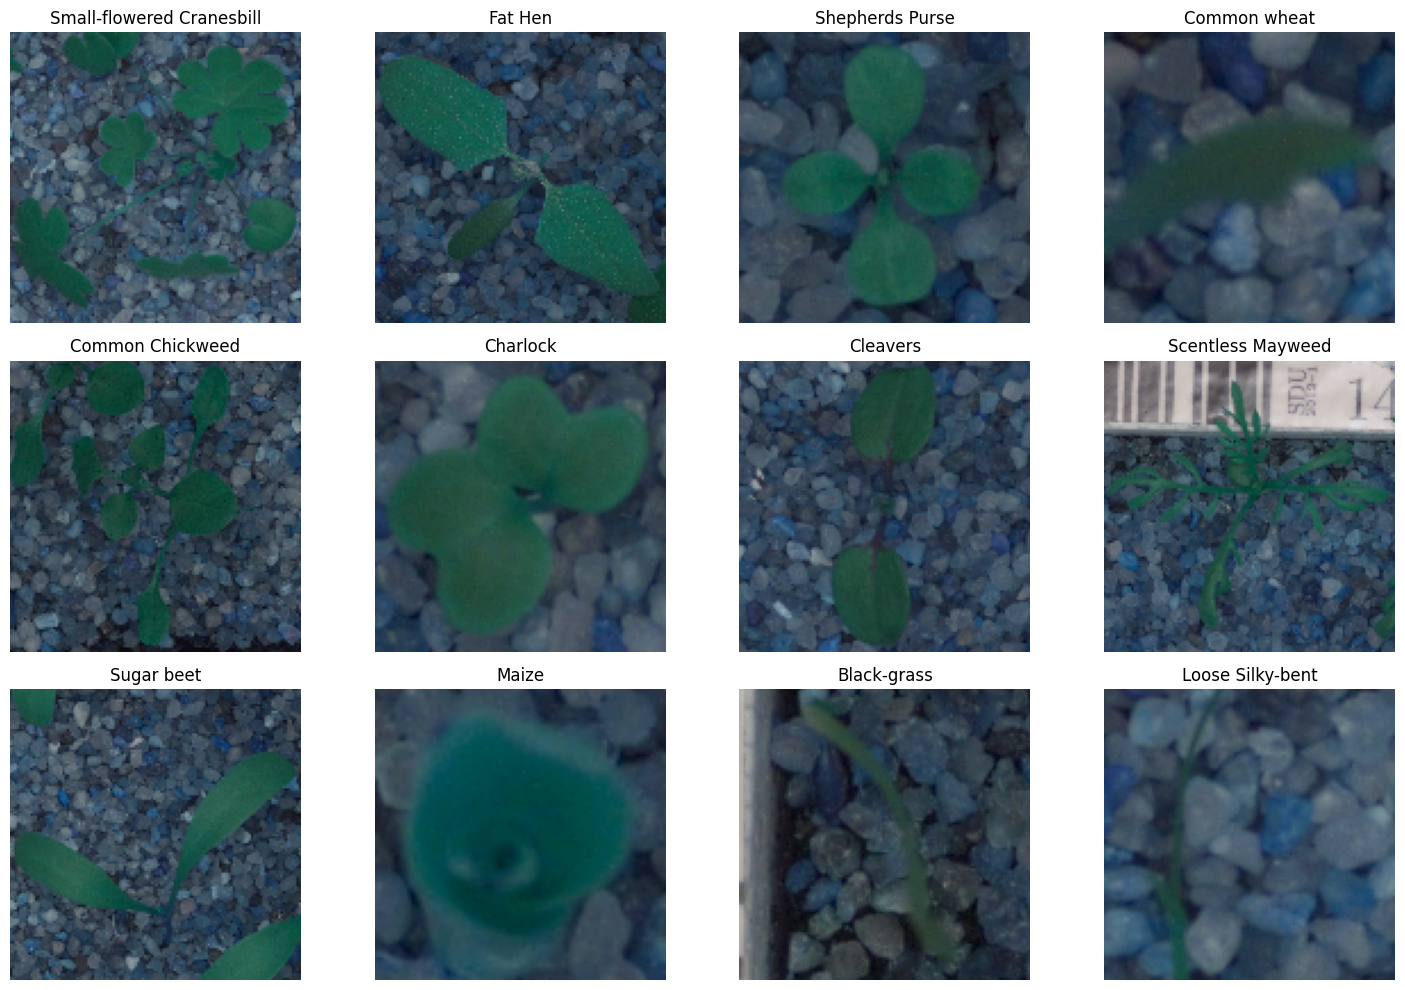

In [ ]:
unique_labels = labels['Label'].unique()
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
axes = axes.flatten()

for i, label in enumerate(unique_labels):
    # Get indices of all images with this label
    indices = labels[labels['Label'] == label].index
    # Pick a random index
    random_index = np.random.choice(indices)
    # Plot the image
    axes[i].imshow(images[random_index])
    axes[i].set_title(label)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### Checking the distribution of the target variable

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
 [Text(0, 0, 'Small-flowered Cranesbill'),
  Text(1, 0, 'Fat Hen'),
  Text(2, 0, 'Shepherds Purse'),
  Text(3, 0, 'Common wheat'),
  Text(4, 0, 'Common Chickweed'),
  Text(5, 0, 'Charlock'),
  Text(6, 0, 'Cleavers'),
  Text(7, 0, 'Scentless Mayweed'),
  Text(8, 0, 'Sugar beet'),
  Text(9, 0, 'Maize'),
  Text(10, 0, 'Black-grass'),
  Text(11, 0, 'Loose Silky-bent')])

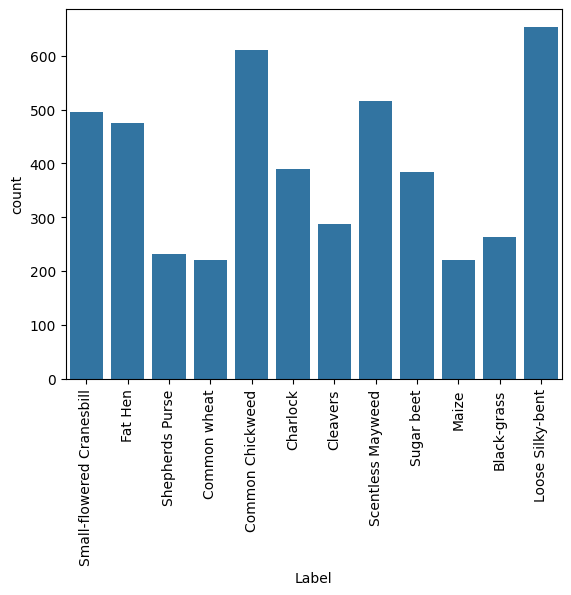

In [ ]:
sns.countplot(x=labels['Label'])            # checking for data imbalance
plt.xticks(rotation='vertical')

Saved array shapes are `(4750, 128, 128, 3)` and `(4750, 1)`. The class-distribution plot shows unequal class frequencies. Array shape alone does not establish RGB versus BGR order.

## Data Pre-Processing

### Channel-order assumption
The historical workflow treated source arrays as BGR and converted to RGB. This assumption cannot be verified from the notebook alone. Set `SOURCE_COLOR_ORDER = 'rgb'` for arrays created by `scripts/prepare_data.py`; they are already RGB. Saved outputs below belong to the original BGR-assumed run.

In [ ]:
SOURCE_COLOR_ORDER = os.environ.get('PLANT_COLOR_ORDER', 'bgr').lower()
if SOURCE_COLOR_ORDER not in {'bgr', 'rgb'}:
    raise ValueError('PLANT_COLOR_ORDER must be rgb or bgr')
if SOURCE_COLOR_ORDER == 'bgr':
    images = np.stack([cv2.cvtColor(image, cv2.COLOR_BGR2RGB) for image in images])


### Resizing images

As the size of the images is large, it may be computationally expensive to train on these larger images; therefore, it is preferable to reduce the image size from 128 to 64.

In [ ]:
images_decreased=[]
height = 64                    # defining the height as 64
width =  64                    # defining the width as 64
dimensions = (width, height)
for i in range(len(images)):
  images_decreased.append( cv2.resize(images[i], dimensions, interpolation=cv2.INTER_LINEAR))

**Image before resizing**

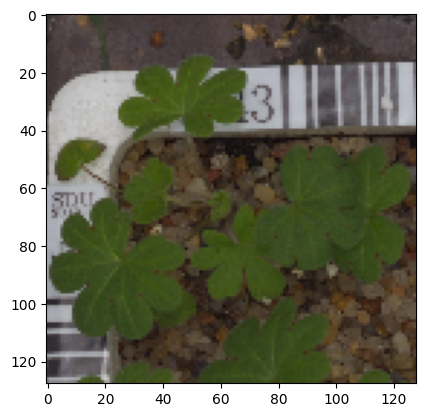

In [ ]:
plt.imshow(images[3])

**Image after resizing**

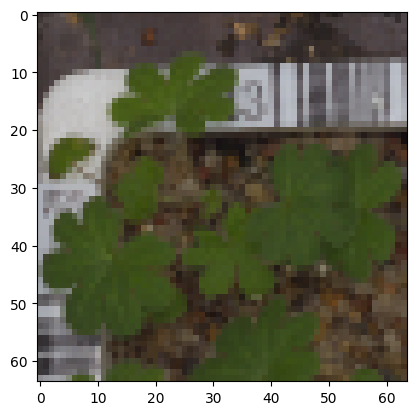

In [ ]:
plt.imshow(images_decreased[3])

### Data Preparation for Modeling


### Data preparation for modelling
Two stratified splits each hold out 10% of their immediate input. The resulting proportions are approximately 81% training, 9% validation and 10% test. Retaining these splits preserves the historical experiment.

In [ ]:
X_temp, X_test, y_temp, y_test = train_test_split(np.array(images_decreased), labels , test_size=0.1, random_state=42,stratify=labels)   # splitting the data with test_size as 0.1
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp , test_size=0.1, random_state=42,stratify=y_temp)                       # splitting the data with test_size as 0.1

In [ ]:
# checking the shape of train, validation and test data
print(X_train.shape,y_train.shape)
print(X_val.shape,y_val.shape)
print(X_test.shape,y_test.shape)

(3847, 64, 64, 3) (3847, 1)
(428, 64, 64, 3) (428, 1)
(475, 64, 64, 3) (475, 1)


### Encoding the target labels

In [ ]:
# Convert labels from names to one hot vectors.
# We have already used encoding methods like onehotencoder and labelencoder earlier so now we will be using a new encoding method called labelBinarizer.
# Labelbinarizer works similar to onehotencoder

enc = LabelBinarizer()                                        # intializing the labelBinarizer
y_train_encoded = enc.fit_transform(y_train)        # fitting and transforming y_train
y_val_encoded=enc.transform(y_val)                  # transforming y_val
y_test_encoded=enc.transform(y_test)                # transforming y_test

In [ ]:
y_train_encoded.shape, y_val_encoded.shape, y_test_encoded.shape    # checking the shape of train, validation and test data

((3847, 12), (428, 12), (475, 12))

### Data Normalization

Since the **image pixel values range from 0-255**, our method of normalization here will be **scaling** - we shall **divide all the pixel values by 255 to standardize the images to have values between 0-1.**

In [ ]:
# normalizing the image pixels of train, test and validation data
X_train_normalized = X_train.astype('float32')/255.0
X_val_normalized = X_val.astype('float32')/255.0
X_test_normalized = X_test.astype('float32')/255.0

The historical workflow resized to 64 × 64, used stratified train/validation/test counts of 3,847 / 428 / 475, one-hot encoded species using `LabelBinarizer`, and divided float32 image pixels by 255. The BGR-to-RGB conversion was an assumption of the original input preparation, not verified by this review.

## Model Building

In [ ]:
# Clearing backend
backend.clear_session()

In [ ]:
# Fixing the seed for random number generators
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

In [ ]:
# Intializing a sequential model
model1 = Sequential()                             # intializing a sequential model

# adding the first conv layer with 128 filters and kernel size 3x3 , padding 'same' provides the output size same as the input size
# Input_shape denotes input image dimension of images
model1.add(Conv2D(128, (3, 3), activation='relu', padding="same", input_shape=(64, 64, 3)))

# adding the max pooling to reduce the size of output of first conv layer
model1.add(MaxPooling2D((2, 2), padding = 'same'))

# creating two similar convolution and max-pooling layers activation = relu
model1.add(Conv2D(64, (3, 3), activation='relu', padding="same"))
model1.add(MaxPooling2D((2, 2), padding = 'same'))

model1.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model1.add(MaxPooling2D((2, 2), padding = 'same'))

# flattening the output of the conv layer after max pooling to make it ready for creating dense connections
model1.add(Flatten())

# adding a fully connected dense layer with 16 neurons
model1.add(Dense(16, activation='relu'))
model1.add(Dropout(0.3))
# adding the output layer with 12 neurons and activation functions as softmax since this is a multi-class classification problem
model1.add(Dense(12, activation='softmax'))

# using the Adam Optimizer
opt=Adam()
# Compiling the model using suitable metric for loss fucntion
model1.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

# generating the summary of the model
model1.summary()


Model: "sequential"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 128)    │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤

 Total params: 128,828 (503.23 KB)


 Trainable params: 128,828 (503.23 KB)


 Non-trainable params: 0 (0.00 B)


<b> Fitting the model on the train data

In [ ]:
# fitting the model on train and also using the validation data for validation
history_1 = model1.fit(
            X_train_normalized, y_train_encoded,
            epochs=30,
            validation_data=(X_val_normalized,y_val_encoded),
            batch_size=32,
            verbose=2
)


Epoch 1/30
121/121 - 16s - 131ms/step - accuracy: 0.1398 - loss: 2.4531 - val_accuracy: 0.1986 - val_loss: 2.3124
Epoch 2/30
121/121 - 2s - 15ms/step - accuracy: 0.2321 - loss: 2.2005 - val_accuracy: 0.3318 - val_loss: 1.9785
Epoch 3/30
121/121 - 2s - 15ms/step - accuracy: 0.2867 - loss: 1.9961 - val_accuracy: 0.3481 - val_loss: 1.7892
Epoch 4/30
121/121 - 2s - 15ms/step - accuracy: 0.2943 - loss: 1.9281 - val_accuracy: 0.3551 - val_loss: 1.7520
Epoch 5/30
121/121 - 2s - 14ms/step - accuracy: 0.2995 - loss: 1.8805 - val_accuracy: 0.3692 - val_loss: 1.7659
Epoch 6/30
121/121 - 2s - 14ms/step - accuracy: 0.3122 - loss: 1.8501 - val_accuracy: 0.4206 - val_loss: 1.6736
Epoch 7/30
121/121 - 2s - 14ms/step - accuracy: 0.3345 - loss: 1.7867 - val_accuracy: 0.4556 - val_loss: 1.6398
Epoch 8/30
121/121 - 2s - 14ms/step - accuracy: 0.3553 - loss: 1.7721 - val_accuracy: 0.4790 - val_loss: 1.5495
Epoch 9/30
121/121 - 2s - 14ms/step - accuracy: 0.3785 - loss: 1.7033 - val_accuracy: 0.5187 - val_los

**Model Evaluation**

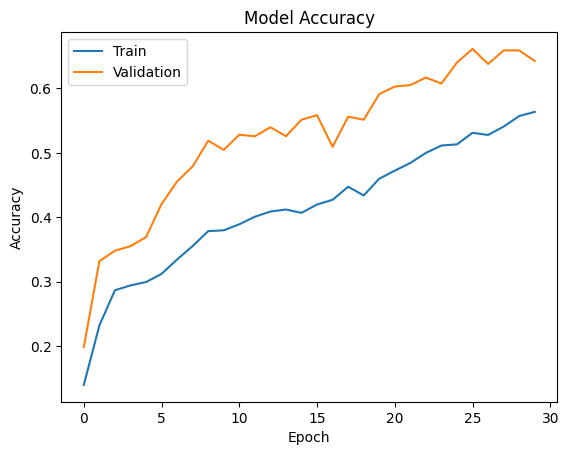

In [ ]:
plt.plot(history_1.history['accuracy'])
plt.plot(history_1.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

**Evaluate the model on test data**

In [ ]:
accuracy = model1.evaluate(X_test_normalized, y_test_encoded, verbose=2)    # evaluating the model on test data


15/15 - 1s - 66ms/step - accuracy: 0.6358 - loss: 1.1147


**Plotting the Confusion Matrix**

In [ ]:
# Here we would get the output as probablities for each category
y_pred=model1.predict(X_test_normalized)                          # predicting the output probabilities


15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step


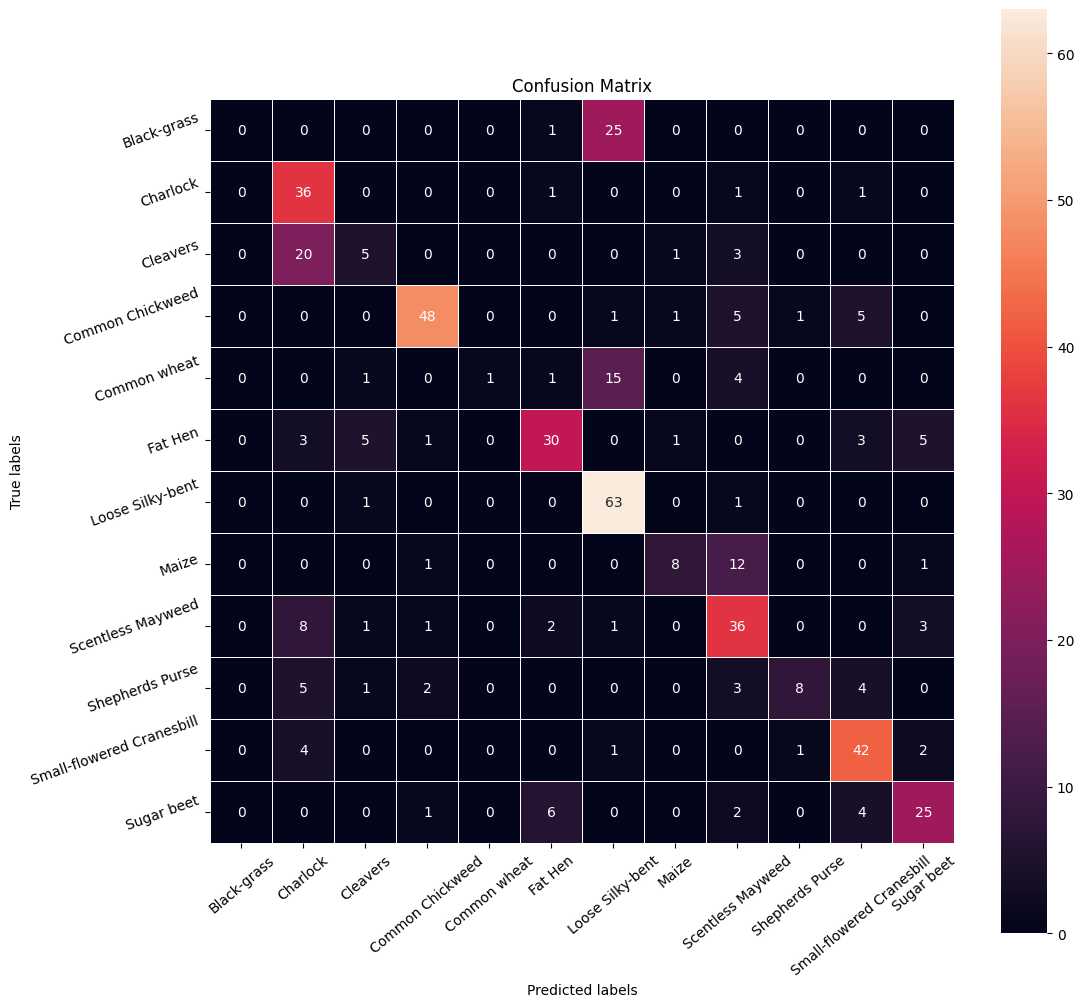

In [ ]:
# Obtaining the categorical values from y_test_encoded and y_pred
y_pred_arg=np.argmax(y_pred,axis=1)
y_test_arg=np.argmax(y_test_encoded,axis=1)

# Plotting the Confusion Matrix using confusion matrix() function which is also predefined in tensorflow module
confusion_matrix = tf.math.confusion_matrix(y_test_arg, y_pred_arg)              # plotting the confusion matrix
f, ax = plt.subplots(figsize=(12, 12))
sns.heatmap(
    confusion_matrix,
    annot=True,
    linewidths=.4,
    fmt="d",
    square=True,
    ax=ax
)
# Setting the labels to both the axes
ax.set_xlabel('Predicted labels');ax.set_ylabel('True labels');
ax.set_title('Confusion Matrix');
ax.xaxis.set_ticklabels(list(enc.classes_),rotation=40)
ax.yaxis.set_ticklabels(list(enc.classes_),rotation=20)
plt.show()


**Plotting Classification Report**

In [ ]:
from sklearn import metrics
# Plotting the classification report
cr=metrics.classification_report(y_test_arg, y_pred_arg)
print(cr)


              precision    recall  f1-score   support

           0       0.00      0.00      0.00        26
           1       0.47      0.92      0.63        39
           2       0.36      0.17      0.23        29
           3       0.89      0.79      0.83        61
           4       1.00      0.05      0.09        22
           5       0.73      0.62      0.67        48
           6       0.59      0.97      0.74        65
           7       0.73      0.36      0.48        22
           8       0.54      0.69      0.61        52
           9       0.80      0.35      0.48        23
          10       0.71      0.84      0.77        50
          11       0.69      0.66      0.68        38

    accuracy                           0.64       475
   macro avg       0.63      0.54      0.52       475
weighted avg       0.64      0.64      0.59       475



## Baseline results: corrected interpretation
Saved test output: accuracy **0.6358**, loss **1.1147**, N = **475**. Macro F1 = **0.52** and weighted F1 = **0.59** are rounded saved report values.

Using the class order labelled on the saved confusion matrices: Common Chickweed has F1 0.83, Small-flowered Cranesbill 0.77, and Loose Silky-bent 0.74. Black-grass has F1 0.00; Common wheat has recall 0.05. The original narrative assigned several of these scores to the wrong species.

Training accuracy is 0.5636 and validation accuracy 0.6425 at epoch 30. These figures alone do not diagnose a specific cause or prove overfitting/underfitting. Training metrics also include dropout effects.

## Model Performance Improvement

**Reducing the Learning Rate:**

**ReduceLRonPlateau()** is a function that will be used to decrease the learning rate by some factor, if the loss is not decreasing for some time. This may start decreasing the loss at a smaller learning rate. There is a possibility that the loss may still not decrease. This may lead to executing the learning rate reduction again in an attempt to achieve a lower loss.

In [ ]:
# monitoring val_accuracy
learning_rate_reduction = ReduceLROnPlateau(monitor='val_accuracy',
                                            patience=3,
                                            verbose=1,
                                            factor=0.5,
                                            min_lr=0.00001)


### **Data Augmentation**

In [ ]:
# Clearing backend
from tensorflow.keras import backend
backend.clear_session()

# Fixing the seed for random number generators
import random
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

In [ ]:
# setting the rotation_range to 20
train_datagen = ImageDataGenerator(
                              rotation_range=20,
                              fill_mode='nearest'
                              )

In [ ]:
# Intializing a sequential model
model2 = Sequential()

# adding the first conv layer with 64 filters and kernel size 3x3 , padding 'same' provides the output size same as the input size
# Input_shape denotes input image dimension images
model2.add(Conv2D(64, (3, 3), activation='relu', padding="same", input_shape=(64, 64, 3)))

# adding max pooling to reduce the size of output of first conv layer
model2.add(MaxPooling2D((2, 2), padding = 'same'))


model2.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model2.add(MaxPooling2D((2, 2), padding = 'same'))
model2.add(BatchNormalization())

# flattening the output of the conv layer after max pooling to make it ready for creating dense connections
model2.add(Flatten())

# Adding a fully connected dense layer with 16 neurons
model2.add(Dense(16, activation='relu'))

# adding dropout with dropout_rate=0.3
model2.add(Dropout(0.3))
# adding the output layer with 12 neurons and activation functions as softmax since this is a multi-class classification problem
model2.add(Dense(12, activation='softmax'))

# Initialize Adam optimizer
opt=Adam()
# Compile model
model2.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

# Generating the summary of the model
model2.summary()


Model: "sequential"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │

 Total params: 151,676 (592.48 KB)


 Trainable params: 151,612 (592.23 KB)


 Non-trainable params: 64 (256.00 B)


<b> Fitting the model on the train data

In [ ]:
# fitting the model on train data with batch_size=64 and epochs=30
# Epochs
epochs = 30
# Batch size
batch_size = 64

history = model2.fit(train_datagen.flow(X_train_normalized,y_train_encoded,
                                       batch_size=batch_size,
                                       shuffle=False),
                                       epochs=epochs,
                                       steps_per_epoch=X_train_normalized.shape[0] // batch_size,
                                       validation_data=(X_val_normalized,y_val_encoded),
                                       verbose=1,callbacks=[learning_rate_reduction])


Epoch 1/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 14s 134ms/step - accuracy: 0.2218 - loss: 2.2516 - val_accuracy: 0.2593 - val_loss: 2.3899 - learning_rate: 0.0010
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3281 - loss: 1.9145 - val_accuracy: 0.2897 - val_loss: 2.3919 - learning_rate: 0.0010
Epoch 3/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - accuracy: 0.4137 - loss: 1.8160 - val_accuracy: 0.3294 - val_loss: 2.2962 - learning_rate: 0.0010
Epoch 4/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3906 - loss: 1.9174 - val_accuracy: 0.2944 - val_loss: 2.3159 - learning_rate: 0.0010
Epoch 5/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.4827 - loss: 1.5704 - val_accuracy: 0.3855 - val_loss: 2.1674 - learning_rate: 0.0010
Epoch 6/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4531 - loss: 1.6019 - val_accuracy: 0.3808 - val_loss: 2.1827 - learning_rate: 0.0010
Epoch 7/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.5141 - loss: 1.4463 - val_acc

**Model Evaluation**

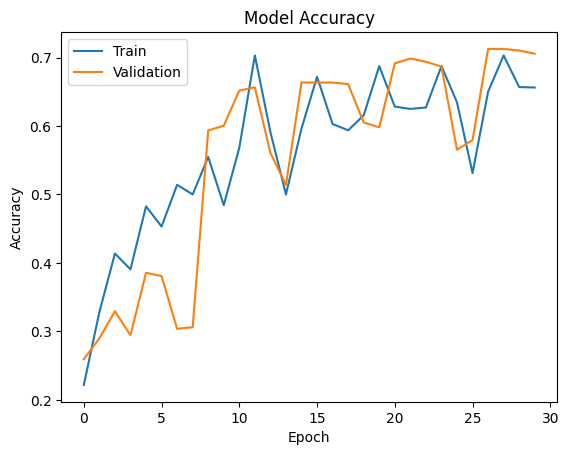

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

**Evaluate the model on test data**

In [ ]:
accuracy = model2.evaluate(X_test_normalized, y_test_encoded, verbose=2)  # evaluating the model on test data


15/15 - 1s - 67ms/step - accuracy: 0.7095 - loss: 0.8945


**Plotting the Confusion Matrix**

In [ ]:
# obtaining the output probabilities
y_pred=model2.predict(X_test_normalized)


15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step


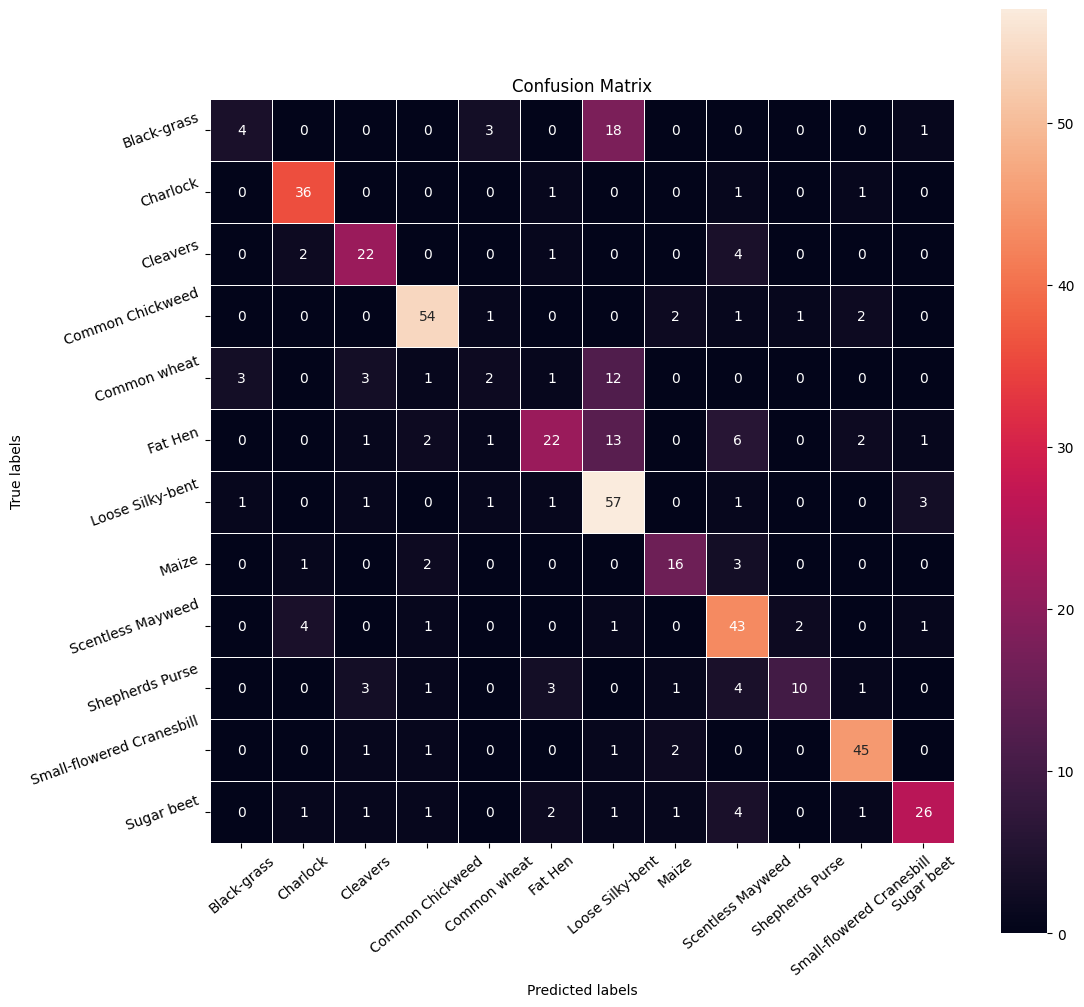

In [ ]:
# Obtaining the categorical values from y_test_encoded and y_pred
y_pred_arg=np.argmax(y_pred,axis=1)
y_test_arg=np.argmax(y_test_encoded,axis=1)

# Plotting the Confusion Matrix using confusion matrix() function which is also predefined in tensorflow module
confusion_matrix = tf.math.confusion_matrix(y_test_arg,y_pred_arg)
f, ax = plt.subplots(figsize=(12, 12))
sns.heatmap(
    confusion_matrix,
    annot=True,
    linewidths=.4,
    fmt="d",
    square=True,
    ax=ax
)
# Setting the labels to both the axes
ax.set_xlabel('Predicted labels');ax.set_ylabel('True labels');
ax.set_title('Confusion Matrix');
ax.xaxis.set_ticklabels(list(enc.classes_),rotation=40)
ax.yaxis.set_ticklabels(list(enc.classes_),rotation=20)
plt.show()


**Plotting Classification Report**

In [ ]:
# Plotting the classification report
cr=metrics.classification_report(y_test_arg, y_pred_arg)
print(cr)


              precision    recall  f1-score   support

           0       0.50      0.15      0.24        26
           1       0.82      0.92      0.87        39
           2       0.69      0.76      0.72        29
           3       0.86      0.89      0.87        61
           4       0.25      0.09      0.13        22
           5       0.71      0.46      0.56        48
           6       0.55      0.88      0.68        65
           7       0.73      0.73      0.73        22
           8       0.64      0.83      0.72        52
           9       0.77      0.43      0.56        23
          10       0.87      0.90      0.88        50
          11       0.81      0.68      0.74        38

    accuracy                           0.71       475
   macro avg       0.68      0.64      0.64       475
weighted avg       0.70      0.71      0.69       475



## Second CNN results: corrected interpretation
Saved test output: accuracy **0.7095**, loss **0.8945**, N = **475**. Macro F1 = **0.64**, weighted F1 = **0.69** (rounded report values). Recorded accuracy is 7.37 percentage points above baseline.

Species-level F1: Small-flowered Cranesbill 0.88; Charlock 0.87; Common Chickweed 0.87. Low recall persists for Black-grass (0.15) and Common wheat (0.09), frequently confused with Loose Silky-bent. Fat Hen F1 is 0.56, not approximately 0.87.

Architecture, augmentation, batch size, normalization and learning-rate scheduling changed together. This is a combined comparison, not evidence for the separate contribution of each technique. The original augmented loop floors steps per epoch and disables shuffling; saved logs alternate between full and extremely short epochs. Treat training exposure cautiously. The standalone script uses full epochs and modern augmentation; it must be evaluated as a new experiment.

## Final Model

### Visualizing the prediction

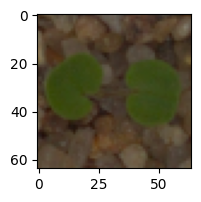

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 641ms/step
Predicted Label ['Small-flowered Cranesbill']
True Label Small-flowered Cranesbill


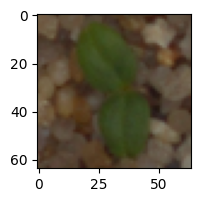

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Predicted Label ['Cleavers']
True Label Cleavers


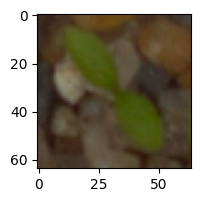

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Predicted Label ['Common Chickweed']
True Label Common Chickweed


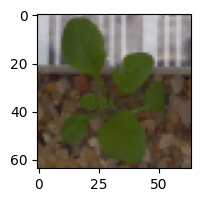

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Predicted Label ['Shepherds Purse']
True Label Shepherds Purse


In [ ]:

# Visualizing the predicted and correct label of images from test data
plt.figure(figsize=(2,2))
plt.imshow(X_test[2])
plt.show()
## predicting the test data using the final model selected
print('Predicted Label', enc.inverse_transform(model2.predict((X_test_normalized[2].reshape(1,64,64,3)))))   # reshaping the input image as we are only trying to predict using a single image
print('True Label', enc.inverse_transform(y_test_encoded)[2])                                               # using inverse_transform() to get the output label from the output vector

plt.figure(figsize=(2,2))
plt.imshow(X_test[33])
plt.show()
## predicting the test data using the final model selected
print('Predicted Label', enc.inverse_transform(model2.predict((X_test_normalized[33].reshape(1,64,64,3)))))  # reshaping the input image as we are only trying to predict using a single image
print('True Label', enc.inverse_transform(y_test_encoded)[33])                                              # using inverse_transform() to get the output label from the output vector

plt.figure(figsize=(2,2))
plt.imshow(X_test[59],)
plt.show()
## predicting the test data using the final model selected
print('Predicted Label', enc.inverse_transform(model2.predict((X_test_normalized[59].reshape(1,64,64,3)))))  # reshaping the input image as we are only trying to predict using a single image
print('True Label', enc.inverse_transform(y_test_encoded)[59])                                              # using inverse_transform() to get the output label from the output vector

plt.figure(figsize=(2,2))
plt.imshow(X_test[36])
plt.show()
## predicting the test data using the final model selected
print('Predicted Label', enc.inverse_transform(model2.predict((X_test_normalized[36].reshape(1,64,64,3)))))  # reshaping the input image as we are only trying to predict using a single image
print('True Label', enc.inverse_transform(y_test_encoded)[36])                                              # using inverse_transform() to get the output label from the output vector


## Actionable Insights and Business Recommendations

1. **Research use:** Treat this model as an educational species-classification prototype. Overall accuracy does not establish reliable crop/weed discrimination or safe herbicide decisions.
2. **Error review:** Prioritize Black-grass versus Loose Silky-bent and Common wheat versus Loose Silky-bent. The saved class mapping corrects the earlier claim that Common Chickweed and Small-flowered Cranesbill were the weakest species.
3. **Validation:** Check exact/near duplicates and repeated physical plants across splits; obtain independent field imagery spanning lighting, cameras, soils and growth stages.
4. **Future experiments:** Compare transfer learning and class-aware strategies using validation data; report per-class recall, macro F1 and uncertainty across repeated runs where feasible.
5. **Deployment research:** Mobile and edge inference, calibrated review thresholds and farmer-facing trials are future work. No deployment-readiness claim is made.

## Attribution
Dataset: Giselsson et al. (2017), *A Public Image Database for Benchmark of Plant Seedling Classification Algorithms*, https://arxiv.org/abs/1711.05458. Official source and terms: https://vision.eng.au.dk/plant-seedlings-dataset/. Original dataset images embedded here retain the upstream terms. See `../NOTICE.md` for other rights and starter-material considerations.